In [1]:

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

from pathlib import Path

DATA_PATH = Path("../data/Data - Sheet1 (1).csv")

df = pd.read_csv(DATA_PATH)

# Convert timestamp
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"],
    errors="coerce"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (2000, 8)


,Timestamp,Service Type,Channel,Revenue,Ad Spend,Conversions,Customer Type,Category
0,2023-06-14 21:00:00,Product,Instagram,128.82,27.67,0,New,Discounted
1,2023-07-10 11:00:00,Product,Google Ads,125.35,6.18,0,Returning,Discounted
2,2023-07-21 08:00:00,Service,Instagram,148.02,9.55,0,Returning,Premium
3,2023-06-11 09:00:00,Product,In-Store,17.44,0.00,0,Returning,Basic
4,2023-07-22 21:00:00,Product,Google Ads,42.51,21.19,1,Returning,Discounted


In [4]:

# Dataset information
df.info()

# Statistical summary
display(df.describe().T)

# Categorical columns
categorical_columns = df.select_dtypes(
    include="object"
).columns

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Timestamp      2000 non-null   datetime64[ns]
 1   Service Type   2000 non-null   object        
 2   Channel        2000 non-null   object        
 3   Revenue        2000 non-null   float64       
 4   Ad Spend       2000 non-null   float64       
 5   Conversions    2000 non-null   int64         
 6   Customer Type  2000 non-null   object        
 7   Category       2000 non-null   object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 125.1+ KB


,count,mean,min,25%,50%,75%,max,std
Timestamp,2000,2023-07-02 04:53:11.399999744,2023-01-01 09:00:00,2023-04-01 10:00:00,2023-06-28 00:30:00,2023-10-03 16:15:00,2024-01-01 21:00:00,NaN
Revenue,"2,000.00",105.87,10.00,58.61,106.01,153.76,199.98,54.94
Ad Spend,"2,000.00",8.57,0.00,0.00,4.22,16.81,29.94,9.79
Conversions,"2,000.00",0.89,0.00,0.00,0.00,2.00,3.00,1.13



Service Type
Service Type
Service    1003
Product     997
Name: count, dtype: int64

Channel
Channel
Google Ads    420
In-Store      420
Online        419
Facebook      375
Instagram     366
Name: count, dtype: int64

Customer Type
Customer Type
Returning    1028
New           972
Name: count, dtype: int64

Category
Category
Premium       689
Basic         663
Discounted    648
Name: count, dtype: int64


In [5]:

# Missing values
print("Missing Values:")
display(df.isnull().sum())

# Exact duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Invalid timestamps
print("Invalid Timestamps:",
      df["Timestamp"].isna().sum())

# Negative values
numeric_columns = [
    "Revenue",
    "Ad Spend",
    "Conversions"
]

print("Negative Values:")
display((df[numeric_columns] < 0).sum())

# Unique values
print("Unique Values:")
display(df.nunique())


Missing Values:


Timestamp        0
Service Type     0
Channel          0
Revenue          0
Ad Spend         0
Conversions      0
Customer Type    0
Category         0
dtype: int64

Duplicate Rows: 0
Invalid Timestamps: 0
Negative Values:


Revenue        0
Ad Spend       0
Conversions    0
dtype: int64

Unique Values:


Timestamp        1699
Service Type        2
Channel             5
Revenue          1893
Ad Spend          956
Conversions         4
Customer Type       2
Category            3
dtype: int64

In [6]:

# Extract date components
df["Year"] = df["Timestamp"].dt.year
df["Month"] = df["Timestamp"].dt.month
df["Month_Name"] = df["Timestamp"].dt.month_name()

df["Day"] = df["Timestamp"].dt.day
df["Day_Name"] = df["Timestamp"].dt.day_name()

df["Hour"] = df["Timestamp"].dt.hour

# Weekend definition: Friday + Saturday
df["Day_Type"] = np.where(
    df["Timestamp"].dt.dayofweek.isin([4, 5]),
    "Weekend",
    "Weekday"
)

# Separate sales and marketing channels
sales_channels = ["Online", "In-Store"]

marketing_channels = [
    "Facebook",
    "Instagram",
    "Google Ads"
]

df["Channel_Type"] = np.select(
    [
        df["Channel"].isin(sales_channels),
        df["Channel"].isin(marketing_channels)
    ],
    [
        "Sales Channel",
        "Marketing Channel"
    ],
    default="Unknown"
)

display(df.head())


,Timestamp,Service Type,Channel,Revenue,Ad Spend,Conversions,Customer Type,Category,Year,Month,Month_Name,Day,Day_Name,Hour,Day_Type,Channel_Type
0,2023-06-14 21:00:00,Product,Instagram,128.82,27.67,0,New,Discounted,2023,6,June,14,Wednesday,21,Weekday,Marketing Channel
1,2023-07-10 11:00:00,Product,Google Ads,125.35,6.18,0,Returning,Discounted,2023,7,July,10,Monday,11,Weekday,Marketing Channel
2,2023-07-21 08:00:00,Service,Instagram,148.02,9.55,0,Returning,Premium,2023,7,July,21,Friday,8,Weekend,Marketing Channel
3,2023-06-11 09:00:00,Product,In-Store,17.44,0.00,0,Returning,Basic,2023,6,June,11,Sunday,9,Weekday,Sales Channel
4,2023-07-22 21:00:00,Product,Google Ads,42.51,21.19,1,Returning,Discounted,2023,7,July,22,Saturday,21,Weekend,Marketing Channel


count   2,000.00
mean      105.87
std        54.94
min        10.00
25%        58.61
50%       106.01
75%       153.76
max       199.98
Name: Revenue, dtype: float64

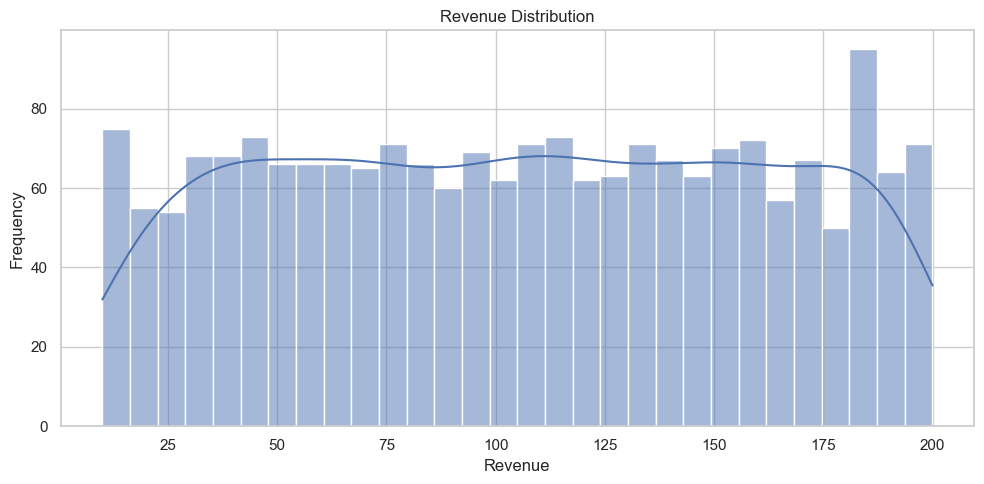

In [7]:

# Revenue statistical analysis

revenue_stats = df["Revenue"].describe()

display(revenue_stats)

# Revenue distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Revenue",
    bins=30,
    kde=True
)

plt.title("Revenue Distribution")
plt.xlabel("Revenue")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


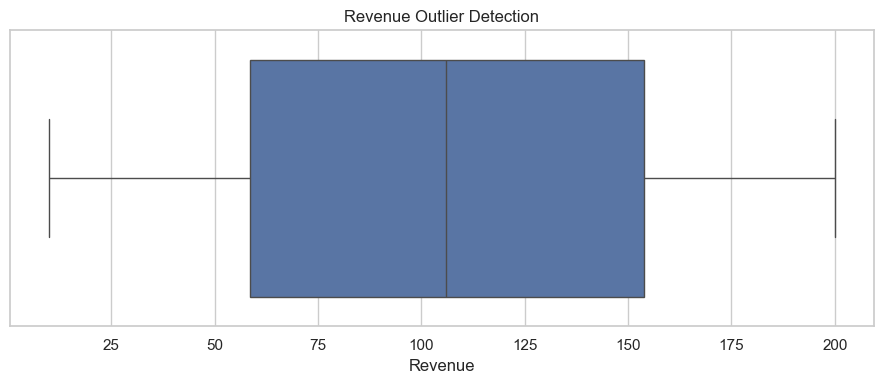

In [9]:

plt.figure(figsize=(9, 4))

sns.boxplot(
    data=df,
    x="Revenue"
)

plt.title("Revenue Outlier Detection")
plt.xlabel("Revenue")

plt.tight_layout()
plt.show()


In [10]:

monthly_sales = (
    df.groupby("Month")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Transactions=("Revenue", "count"),
        Average_Revenue=("Revenue", "mean"),
        Ad_Spend=("Ad Spend", "sum")
    )
    .reset_index()
)

# Exclude incomplete January 2024
monthly_complete = monthly_sales[
    monthly_sales["Month"] != "2024-01"
].copy()

display(monthly_complete)


,Month,Total_Revenue,Transactions,Average_Revenue,Ad_Spend
0,1,"16,973.47",170,99.84,"1,434.83"
1,2,"16,810.96",160,105.07,"1,580.17"
2,3,"18,517.78",173,107.04,"1,390.99"
3,4,"19,030.02",173,110.00,"1,436.07"
4,5,"18,615.59",177,105.17,"1,672.53"
5,6,"16,906.13",168,100.63,"1,307.35"
6,7,"15,587.12",154,101.22,"1,400.78"
7,8,"17,337.88",164,105.72,"1,332.22"
8,9,"16,429.51",155,106.00,"1,168.38"
9,10,"17,140.46",158,108.48,"1,461.80"


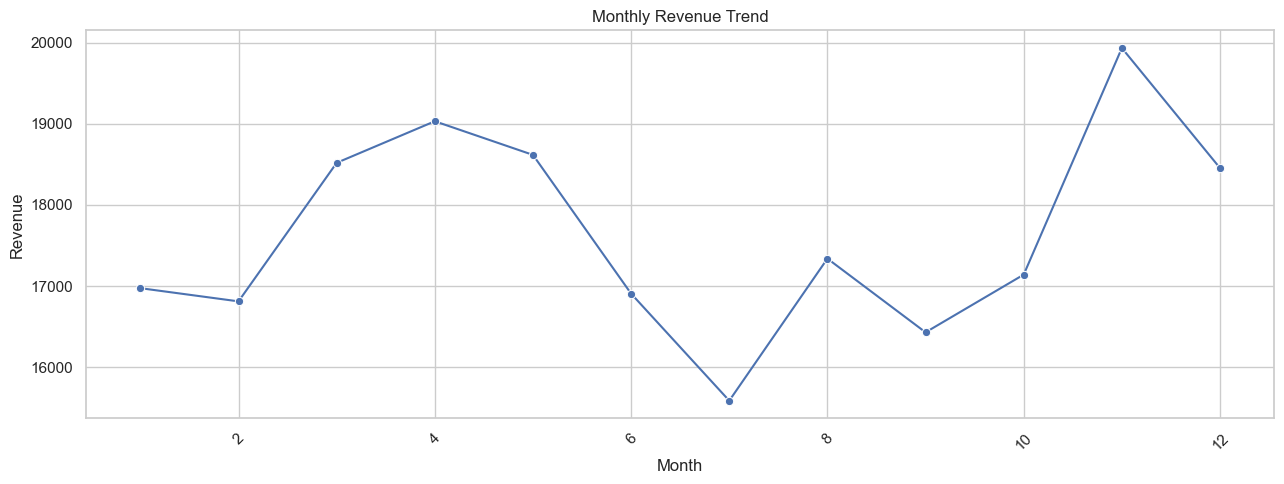

In [11]:

plt.figure(figsize=(13, 5))

sns.lineplot(
    data=monthly_complete,
    x="Month",
    y="Total_Revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [12]:

sales_channels = ["Online", "In-Store"]

sales_df = df[
    df["Channel"].isin(sales_channels)
].copy()

channel_analysis = (
    sales_df.groupby("Channel")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Transactions=("Revenue", "count"),
        Average_Order_Value=("Revenue", "mean")
    )
    .reset_index()
)

channel_analysis["Revenue_Share"] = (
    channel_analysis["Total_Revenue"]
    / channel_analysis["Total_Revenue"].sum()
    * 100
)

display(channel_analysis)


,Channel,Total_Revenue,Transactions,Average_Order_Value,Revenue_Share
0,In-Store,"42,720.34",420,101.72,48.66
1,Online,"45,080.31",419,107.59,51.34


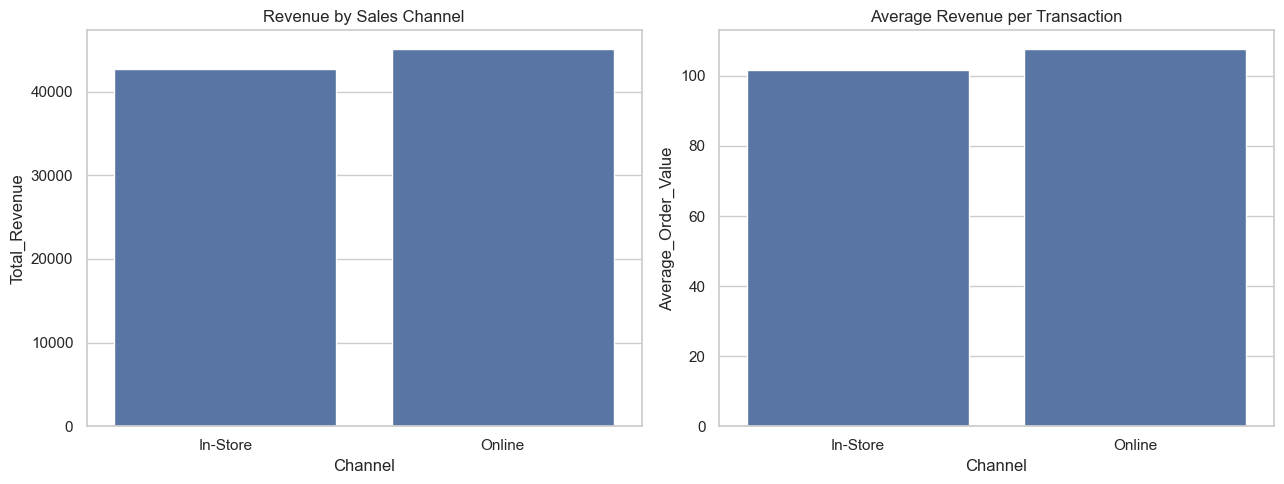

In [13]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=channel_analysis,
    x="Channel",
    y="Total_Revenue",
    ax=axes[0]
)

axes[0].set_title("Revenue by Sales Channel")

sns.barplot(
    data=channel_analysis,
    x="Channel",
    y="Average_Order_Value",
    ax=axes[1]
)

axes[1].set_title("Average Revenue per Transaction")

plt.tight_layout()
plt.show()


In [14]:

category_analysis = (
    df.groupby("Category")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Transactions=("Revenue", "count"),
        Average_Revenue=("Revenue", "mean"),
        Ad_Spend=("Ad Spend", "sum")
    )
    .reset_index()
)

category_analysis["Revenue_Share"] = (
    category_analysis["Total_Revenue"]
    / df["Revenue"].sum()
    * 100
)

display(
    category_analysis.sort_values(
        "Total_Revenue",
        ascending=False
    )
)


,Category,Total_Revenue,Transactions,Average_Revenue,Ad_Spend,Revenue_Share
2,Premium,"74,621.40",689,108.30,"5,851.51",35.24
0,Basic,"68,779.00",663,103.74,"6,019.05",32.48
1,Discounted,"68,333.92",648,105.45,"5,269.78",32.27


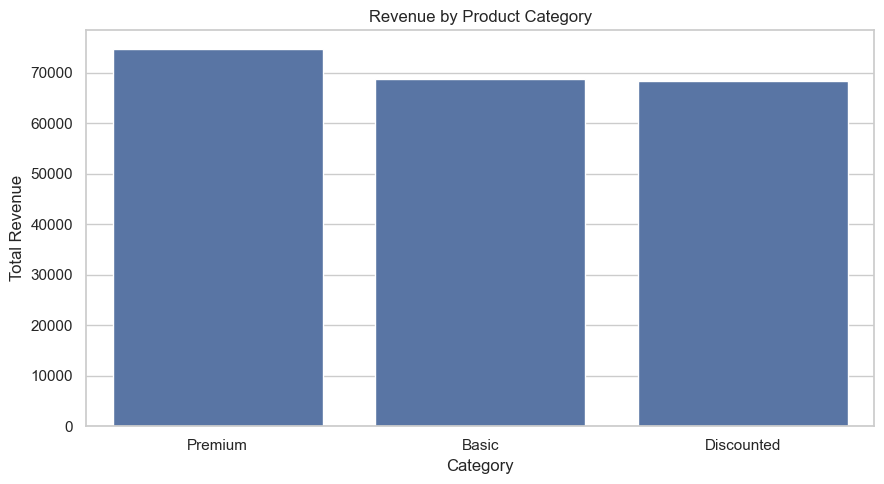

In [15]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_analysis,
    x="Category",
    y="Total_Revenue",
    order=category_analysis.sort_values(
        "Total_Revenue",
        ascending=False
    )["Category"]
)

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")

plt.tight_layout()
plt.show()


In [16]:

customer_analysis = (
    df.groupby("Customer Type")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Transactions=("Revenue", "count"),
        Average_Revenue=("Revenue", "mean")
    )
    .reset_index()
)

customer_analysis["Revenue_Share"] = (
    customer_analysis["Total_Revenue"]
    / df["Revenue"].sum()
    * 100
)

display(customer_analysis)


,Customer Type,Total_Revenue,Transactions,Average_Revenue,Revenue_Share
0,New,"102,290.15",972,105.24,48.31
1,Returning,"109,444.17",1028,106.46,51.69


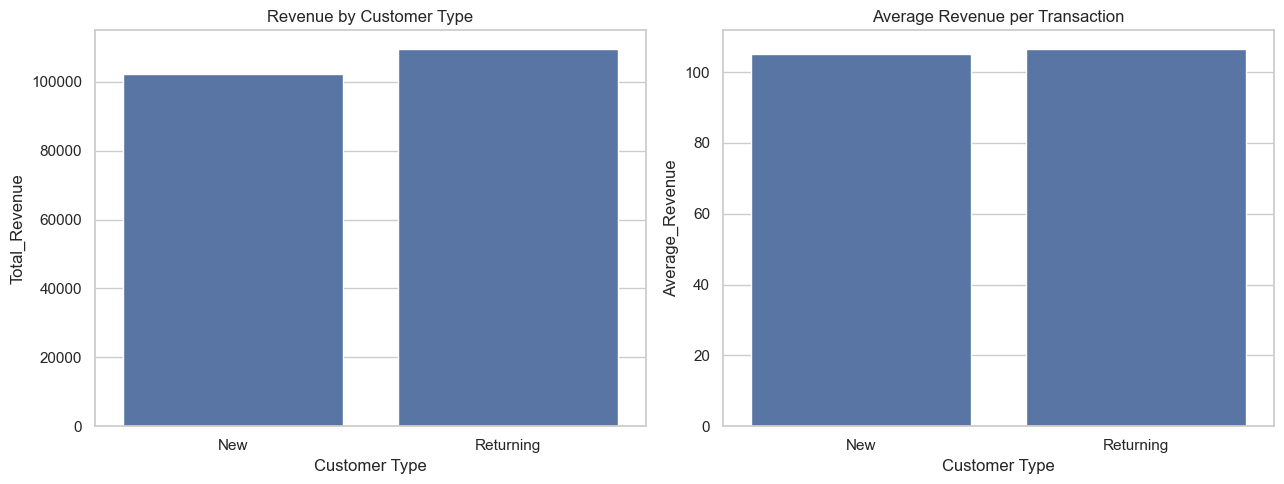

In [17]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=customer_analysis,
    x="Customer Type",
    y="Total_Revenue",
    ax=axes[0]
)

axes[0].set_title("Revenue by Customer Type")

sns.barplot(
    data=customer_analysis,
    x="Customer Type",
    y="Average_Revenue",
    ax=axes[1]
)

axes[1].set_title("Average Revenue per Transaction")

plt.tight_layout()
plt.show()


In [18]:

daily_analysis = (
    df.groupby("Day_Name")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Transactions=("Revenue", "count"),
        Average_Revenue=("Revenue", "mean"),
        Ad_Spend=("Ad Spend", "sum"),
        Conversions=("Conversions", "sum")
    )
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
    .reset_index()
)

display(daily_analysis)


,Day_Name,Total_Revenue,Transactions,Average_Revenue,Ad_Spend,Conversions
0,Monday,"31,298.83",298,105.03,"2,472.15",226
1,Tuesday,"32,503.81",301,107.99,"2,797.38",261
2,Wednesday,"28,219.21",270,104.52,"2,425.32",274
3,Thursday,"32,451.17",285,113.86,"2,357.15",280
4,Friday,"29,109.33",274,106.24,"2,505.79",257
5,Saturday,"24,926.46",261,95.50,"1,880.49",193
6,Sunday,"33,225.51",311,106.83,"2,702.06",285


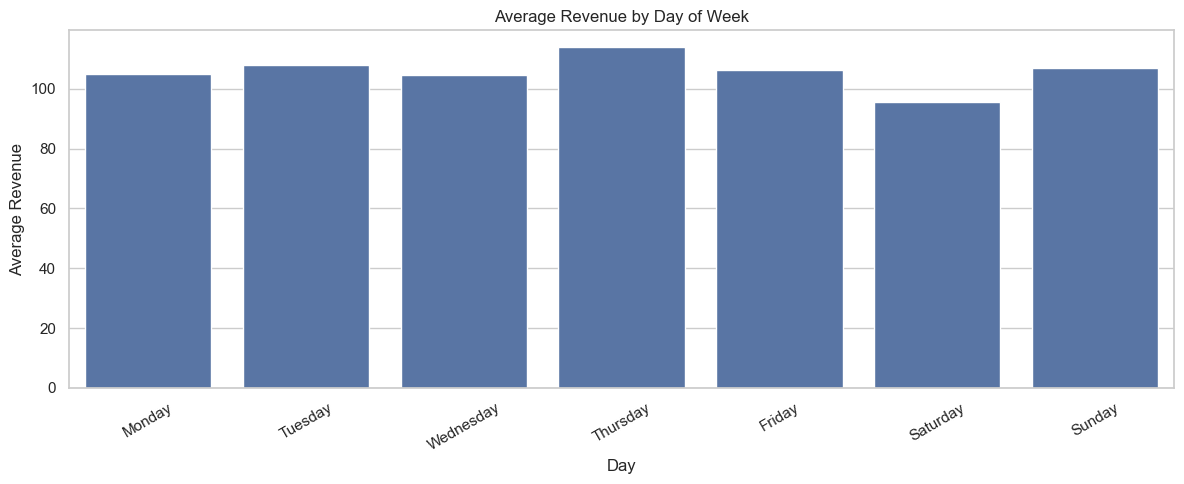

In [19]:

plt.figure(figsize=(12, 5))

sns.barplot(
    data=daily_analysis,
    x="Day_Name",
    y="Average_Revenue"
)

plt.title("Average Revenue by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Revenue")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [20]:

weekend_analysis = (
    df.groupby("Day_Type")
    .agg(
        Revenue=("Revenue", "sum"),
        Transactions=("Revenue", "count"),
        Average_Revenue=("Revenue", "mean"),
        Ad_Spend=("Ad Spend", "sum"),
        Conversions=("Conversions", "sum")
    )
    .reset_index()
)

weekend_analysis["Revenue_Share"] = (
    weekend_analysis["Revenue"]
    / df["Revenue"].sum()
    * 100
)

display(weekend_analysis)


,Day_Type,Revenue,Transactions,Average_Revenue,Ad_Spend,Conversions,Revenue_Share
0,Weekday,"157,698.53",1465,107.64,"12,754.06",1326,74.48
1,Weekend,"54,035.79",535,101.00,"4,386.28",450,25.52


In [21]:

weekend_category = (
    df.groupby(["Day_Type", "Category"])
    .agg(
        Revenue=("Revenue", "sum"),
        Transactions=("Revenue", "count"),
        Average_Revenue=("Revenue", "mean")
    )
    .reset_index()
)

display(weekend_category)


,Day_Type,Category,Revenue,Transactions,Average_Revenue
0,Weekday,Basic,"49,562.95",472,105.01
1,Weekday,Discounted,"51,210.51",479,106.91
2,Weekday,Premium,"56,925.07",514,110.75
3,Weekend,Basic,"19,216.05",191,100.61
4,Weekend,Discounted,"17,123.41",169,101.32
5,Weekend,Premium,"17,696.33",175,101.12


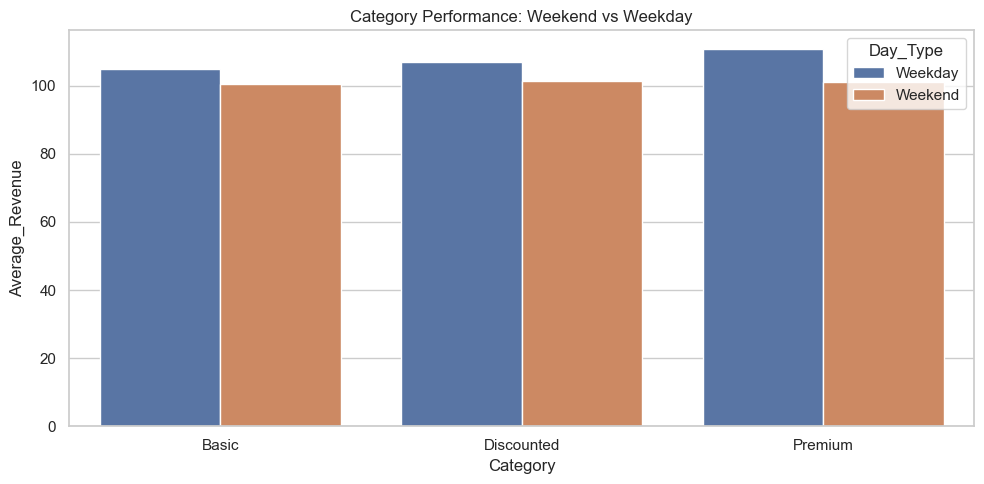

In [22]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekend_category,
    x="Category",
    y="Average_Revenue",
    hue="Day_Type"
)

plt.title("Category Performance: Weekend vs Weekday")
plt.tight_layout()
plt.show()


In [23]:

weekend_customers = (
    df.groupby(["Day_Type", "Customer Type"])
    .agg(
        Revenue=("Revenue", "sum"),
        Transactions=("Revenue", "count"),
        Average_Revenue=("Revenue", "mean")
    )
    .reset_index()
)

display(weekend_customers)


,Day_Type,Customer Type,Revenue,Transactions,Average_Revenue
0,Weekday,New,"76,490.13",712,107.43
1,Weekday,Returning,"81,208.40",753,107.85
2,Weekend,New,"25,800.02",260,99.23
3,Weekend,Returning,"28,235.77",275,102.68


In [24]:

marketing_channels = [
    "Facebook",
    "Instagram",
    "Google Ads"
]

marketing_df = df[
    df["Channel"].isin(marketing_channels)
].copy()

marketing_analysis = (
    marketing_df.groupby("Channel")
    .agg(
        Revenue=("Revenue", "sum"),
        Ad_Spend=("Ad Spend", "sum"),
        Conversions=("Conversions", "sum"),
        Transactions=("Revenue", "count")
    )
    .reset_index()
)

marketing_analysis["ROAS_Proxy"] = (
    marketing_analysis["Revenue"]
    / marketing_analysis["Ad_Spend"]
)

marketing_analysis["Cost_Per_Conversion"] = (
    marketing_analysis["Ad_Spend"]
    / marketing_analysis["Conversions"].replace(0, np.nan)
)

display(
    marketing_analysis.sort_values(
        "ROAS_Proxy",
        ascending=False
    )
)


,Channel,Revenue,Ad_Spend,Conversions,Transactions,ROAS_Proxy,Cost_Per_Conversion
0,Facebook,"41,710.05","5,313.47",575,375,7.85,9.24
2,Instagram,"38,614.95","5,511.23",547,366,7.01,10.08
1,Google Ads,"43,608.67","6,315.64",654,420,6.90,9.66


In [25]:

weekend_marketing = (
    df[df["Channel"].isin(marketing_channels)]
    .groupby(["Day_Type", "Channel"])
    .agg(
        Revenue=("Revenue", "sum"),
        Ad_Spend=("Ad Spend", "sum"),
        Conversions=("Conversions", "sum")
    )
    .reset_index()
)

weekend_marketing["ROAS_Proxy"] = (
    weekend_marketing["Revenue"]
    / weekend_marketing["Ad_Spend"]
)

weekend_marketing["CPA"] = (
    weekend_marketing["Ad_Spend"]
    / weekend_marketing["Conversions"].replace(0, np.nan)
)

display(weekend_marketing)


,Day_Type,Channel,Revenue,Ad_Spend,Conversions,ROAS_Proxy,CPA
0,Weekday,Facebook,"30,263.39","3,789.77",416,7.99,9.11
1,Weekday,Google Ads,"33,851.37","4,761.45",489,7.11,9.74
2,Weekday,Instagram,"29,258.91","4,202.84",421,6.96,9.98
3,Weekend,Facebook,"11,446.66","1,523.70",159,7.51,9.58
4,Weekend,Google Ads,"9,757.30","1,554.19",165,6.28,9.42
5,Weekend,Instagram,"9,356.04","1,308.39",126,7.15,10.38


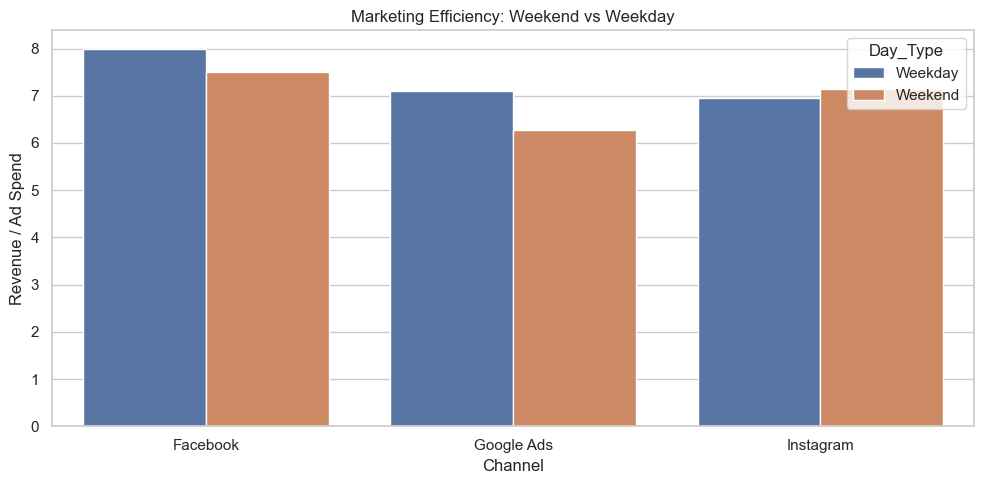

In [26]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekend_marketing,
    x="Channel",
    y="ROAS_Proxy",
    hue="Day_Type"
)

plt.title("Marketing Efficiency: Weekend vs Weekday")
plt.ylabel("Revenue / Ad Spend")

plt.tight_layout()
plt.show()


In [27]:

from pathlib import Path

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df.to_csv(
    OUTPUT_DIR / "thread_theory_cleaned.csv",
    index=False
)

print("Processed dataset saved successfully!")


Processed dataset saved successfully!


In [28]:

# Separate direct sales channels
sales_df = df[
    df["Channel"].isin(["Online", "In-Store"])
].copy()

sales_performance = (
    sales_df.groupby("Channel")
    .agg(
        Revenue=("Revenue", "sum"),
        Transactions=("Revenue", "count"),
        Average_Order_Value=("Revenue", "mean")
    )
    .reset_index()
)

sales_performance["Revenue_Share"] = (
    sales_performance["Revenue"]
    / sales_performance["Revenue"].sum()
    * 100
)

sales_performance["Transaction_Share"] = (
    sales_performance["Transactions"]
    / sales_performance["Transactions"].sum()
    * 100
)

display(sales_performance.round(2))


,Channel,Revenue,Transactions,Average_Order_Value,Revenue_Share,Transaction_Share
0,In-Store,"42,720.34",420,101.72,48.66,50.06
1,Online,"45,080.31",419,107.59,51.34,49.94


In [31]:

period_channel = (
    df.groupby(["Day_Type", "Channel"])
    .agg(
        Revenue=("Revenue", "sum"),
        Transactions=("Revenue", "count"),
        Average_Revenue=("Revenue", "mean"),
        Ad_Spend=("Ad Spend", "sum"),
        Conversions=("Conversions", "sum")
    )
    .reset_index()
)

display(
    period_channel.sort_values(
        ["Channel", "Day_Type"]
    ).round(2)
)


,Day_Type,Channel,Revenue,Transactions,Average_Revenue,Ad_Spend,Conversions
0,Weekday,Facebook,"30,263.39",269,112.50,"3,789.77",416
5,Weekend,Facebook,"11,446.66",106,107.99,"1,523.70",159
1,Weekday,Google Ads,"33,851.37",313,108.15,"4,761.45",489
6,Weekend,Google Ads,"9,757.30",107,91.19,"1,554.19",165
2,Weekday,In-Store,"32,404.75",315,102.87,0.00,0
7,Weekend,In-Store,"10,315.59",105,98.24,0.00,0
3,Weekday,Instagram,"29,258.91",278,105.25,"4,202.84",421
8,Weekend,Instagram,"9,356.04",88,106.32,"1,308.39",126
4,Weekday,Online,"31,920.11",290,110.07,0.00,0
9,Weekend,Online,"13,160.20",129,102.02,0.00,0


In [33]:

weekend_days = ["Friday", "Saturday"]

weekend_daily = (
    df[df["Day_Name"].isin(weekend_days)]
    .groupby(["Day_Name", "Channel"])
    .agg(
        Revenue=("Revenue", "sum"),
        Transactions=("Revenue", "count"),
        Average_Revenue=("Revenue", "mean")
    )
    .reset_index()
)

display(
    weekend_daily.sort_values(
        ["Day_Name", "Average_Revenue"],
        ascending=[True, False]
    ).round(2)
)


,Day_Name,Channel,Revenue,Transactions,Average_Revenue
0,Friday,Facebook,"7,273.44",63,115.45
4,Friday,Online,"6,373.57",57,111.82
2,Friday,In-Store,"5,452.79",52,104.86
3,Friday,Instagram,"4,717.99",46,102.56
1,Friday,Google Ads,"5,291.54",56,94.49
8,Saturday,Instagram,"4,638.05",42,110.43
5,Saturday,Facebook,"4,173.22",43,97.05
9,Saturday,Online,"6,786.63",72,94.26
7,Saturday,In-Store,"4,862.80",53,91.75
6,Saturday,Google Ads,"4,465.76",51,87.56


In [34]:

category_weekend = (
    df.groupby(["Day_Type", "Category"])
    .agg(
        Revenue=("Revenue", "sum"),
        Transactions=("Revenue", "count"),
        Average_Revenue=("Revenue", "mean")
    )
    .reset_index()
)

display(
    category_weekend.pivot(
        index="Category",
        columns="Day_Type",
        values="Average_Revenue"
    ).round(2)
)


Day_Type,Weekday,Weekend
Category,,
Basic,105.01,100.61
Discounted,106.91,101.32
Premium,110.75,101.12


In [35]:

customer_weekend = (
    df.groupby(["Day_Type", "Customer Type"])
    .agg(
        Revenue=("Revenue", "sum"),
        Transactions=("Revenue", "count"),
        Average_Revenue=("Revenue", "mean")
    )
    .reset_index()
)

display(
    customer_weekend.pivot(
        index="Customer Type",
        columns="Day_Type",
        values="Average_Revenue"
    ).round(2)
)


Day_Type,Weekday,Weekend
Customer Type,,
New,107.43,99.23
Returning,107.85,102.68


In [36]:

marketing_df = df[
    df["Channel"].isin([
        "Facebook",
        "Instagram",
        "Google Ads"
    ])
].copy()

marketing_performance = (
    marketing_df.groupby(["Day_Type", "Channel"])
    .agg(
        Revenue=("Revenue", "sum"),
        Ad_Spend=("Ad Spend", "sum"),
        Conversions=("Conversions", "sum")
    )
    .reset_index()
)

marketing_performance["ROAS_Proxy"] = (
    marketing_performance["Revenue"]
    / marketing_performance["Ad_Spend"]
)

marketing_performance["Cost_Per_Conversion"] = (
    marketing_performance["Ad_Spend"]
    / marketing_performance["Conversions"].replace(0, np.nan)
)

display(marketing_performance.round(2))


,Day_Type,Channel,Revenue,Ad_Spend,Conversions,ROAS_Proxy,Cost_Per_Conversion
0,Weekday,Facebook,"30,263.39","3,789.77",416,7.99,9.11
1,Weekday,Google Ads,"33,851.37","4,761.45",489,7.11,9.74
2,Weekday,Instagram,"29,258.91","4,202.84",421,6.96,9.98
3,Weekend,Facebook,"11,446.66","1,523.70",159,7.51,9.58
4,Weekend,Google Ads,"9,757.30","1,554.19",165,6.28,9.42
5,Weekend,Instagram,"9,356.04","1,308.39",126,7.15,10.38


In [37]:

recommendations = []

# 1. Online vs In-Store
channel_avg = sales_df.groupby("Channel")["Revenue"].mean()

online_avg = channel_avg.get("Online", 0)
store_avg = channel_avg.get("In-Store", 0)

if online_avg > store_avg:
    recommendations.append({
        "Area": "Sales Channels",
        "Finding": "Online has higher average transaction revenue.",
        "Recommendation": "Improve online product presentation and checkout.",
        "Priority": "High"
    })
else:
    recommendations.append({
        "Area": "Sales Channels",
        "Finding": "In-Store has higher average transaction revenue.",
        "Recommendation": "Investigate in-store customer experience.",
        "Priority": "High"
    })


# 2. Friday vs Saturday
daily_avg = (
    df[df["Day_Name"].isin(["Friday", "Saturday"])]
    .groupby("Day_Name")["Revenue"]
    .mean()
)

if daily_avg["Saturday"] < daily_avg["Friday"]:
    recommendations.append({
        "Area": "Weekend Sales",
        "Finding": "Saturday average revenue is lower than Friday.",
        "Recommendation": "Test targeted Saturday promotions.",
        "Priority": "High"
    })


# 3. Returning vs New Customers
customer_avg = (
    df.groupby(["Day_Type", "Customer Type"])["Revenue"]
    .mean()
)

if customer_avg["Weekend"]["Returning"] > customer_avg["Weekend"]["New"]:
    recommendations.append({
        "Area": "Customer Strategy",
        "Finding": "Returning customers have higher weekend average revenue.",
        "Recommendation": "Test loyalty rewards for returning customers.",
        "Priority": "Medium"
    })


# 4. Premium Weekend Opportunity
category_avg = (
    df.groupby(["Day_Type", "Category"])["Revenue"]
    .mean()
)

if category_avg["Weekend"]["Premium"] < category_avg["Weekday"]["Premium"]:
    recommendations.append({
        "Area": "Product Strategy",
        "Finding": "Premium average revenue is lower on weekends.",
        "Recommendation": "Test premium bundles or exclusive weekend offers.",
        "Priority": "Medium"
    })


# 5. Marketing Channel
weekend_ads = (
    marketing_df[marketing_df["Day_Type"] == "Weekend"]
    .groupby("Channel")
    .agg(
        Revenue=("Revenue", "sum"),
        Ad_Spend=("Ad Spend", "sum")
    )
)

weekend_ads["ROAS_Proxy"] = (
    weekend_ads["Revenue"] / weekend_ads["Ad_Spend"]
)

best_channel = weekend_ads["ROAS_Proxy"].idxmax()

recommendations.append({
    "Area": "Marketing Strategy",
    "Finding": f"{best_channel} has the highest weekend revenue-to-spend proxy.",
    "Recommendation": f"Run a controlled weekend test for {best_channel}.",
    "Priority": "Medium"
})


# Display recommendations
recommendation_df = pd.DataFrame(recommendations)

display(recommendation_df)


,Area,Finding,Recommendation,Priority
0,Sales Channels,Online has higher average transaction revenue.,Improve online product presentation and checkout.,High
1,Weekend Sales,Saturday average revenue is lower than Friday.,Test targeted Saturday promotions.,High
2,Customer Strategy,Returning customers have higher weekend averag...,Test loyalty rewards for returning customers.,Medium
3,Product Strategy,Premium average revenue is lower on weekends.,Test premium bundles or exclusive weekend offers.,Medium
4,Marketing Strategy,Facebook has the highest weekend revenue-to-sp...,Run a controlled weekend test for Facebook.,Medium


In [38]:

from pathlib import Path

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

recommendation_df.to_csv(
    OUTPUT_DIR / "business_recommendations.csv",
    index=False
)

sales_performance.to_csv(
    OUTPUT_DIR / "sales_performance.csv",
    index=False
)

marketing_performance.to_csv(
    OUTPUT_DIR / "marketing_performance.csv",
    index=False
)

print("Business analysis exported successfully!")


Business analysis exported successfully!


In [39]:

df["Month_Period"] = (
    df["Timestamp"].dt.to_period("M").astype(str)
)

monthly_analysis = (
    df.groupby("Month_Period")
    .agg(
        Revenue=("Revenue", "sum"),
        Transactions=("Revenue", "count"),
        Average_Revenue=("Revenue", "mean")
    )
    .reset_index()
)

# Exclude incomplete January 2024
monthly_analysis = monthly_analysis[
    monthly_analysis["Month_Period"] != "2024-01"
]

display(monthly_analysis)


,Month_Period,Revenue,Transactions,Average_Revenue
0,2023-01,"16,456.00",165,99.73
1,2023-02,"16,810.96",160,105.07
2,2023-03,"18,517.78",173,107.04
3,2023-04,"19,030.02",173,110.00
4,2023-05,"18,615.59",177,105.17
5,2023-06,"16,906.13",168,100.63
6,2023-07,"15,587.12",154,101.22
7,2023-08,"17,337.88",164,105.72
8,2023-09,"16,429.51",155,106.00
9,2023-10,"17,140.46",158,108.48
